In [1]:
import sys
print(sys.executable)

import tensorflow as tf
print(tf.__version__)

/opt/anaconda3/envs/tfenv/bin/python3
2.21.0


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, models, optimizers, utils
from tensorflow.keras.layers import LeakyReLU

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

NUM_CLASSES = 10
INPUT_SHAPE = (32, 32, 3)
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 5e-4

print("TensorFlow version:", tf.__version__)

ModuleNotFoundError: No module named 'matplotlib'

In [4]:
%pip install matplotlib pandas

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 36.0 MB/s  0:00:00 45.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 38.9 MB/s  0:00:00 42.7 MB/s eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 45.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 31.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [matplotlib] 7/8 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, models, optimizers, utils
from tensorflow.keras.layers import LeakyReLU

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

NUM_CLASSES = 10
INPUT_SHAPE = (32, 32, 3)
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 5e-4

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, models, optimizers, utils
from tensorflow.keras.layers import LeakyReLU

In [3]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

NUM_CLASSES = 10
INPUT_SHAPE = (32, 32, 3)
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 5e-4

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [4]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test :", x_test.shape)
print("y_test :", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
x_train: (50000, 32, 32, 3)
y_train: (50000, 1)
x_test : (10000, 32, 32, 3)
y_test : (10000, 1)


/opt/anaconda3/envs/tfenv/lib/python3.11/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


In [5]:
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(50000, 32, 32, 3) (50000, 1) (10000, 32, 32, 3) (10000, 1)


In [6]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train = utils.to_categorical(y_train, NUM_CLASSES)
y_test = utils.to_categorical(y_test, NUM_CLASSES)

print("x_train min/max:", x_train.min(), x_train.max())
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

x_train min/max: 0.0 1.0
y_train shape: (50000, 10)
y_test shape: (10000, 10)


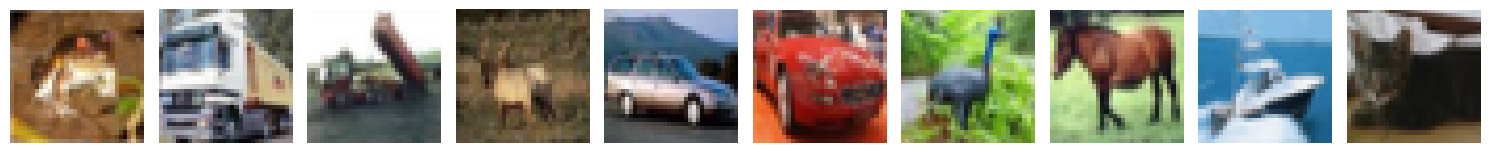

[[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]


In [7]:
def show_images(images, n=10):
    plt.figure(figsize=(15, 3))
    for i in range(min(n, len(images))):
        ax = plt.subplot(1, min(n, len(images)), i + 1)
        ax.imshow(images[i])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_images(x_train[:10], n=10)
print(y_train[:3])

In [8]:
def build_mlp(activation_name="relu"):
    input_layer = layers.Input(shape=INPUT_SHAPE)
    x = layers.Flatten()(input_layer)

    if activation_name == "relu":
        x = layers.Dense(200, activation="relu")(x)
        x = layers.Dense(150, activation="relu")(x)

    elif activation_name == "leaky_relu":
        x = layers.Dense(200)(x)
        x = LeakyReLU(negative_slope=0.01)(x)
        x = layers.Dense(150)(x)
        x = LeakyReLU(negative_slope=0.01)(x)

    elif activation_name == "sigmoid":
        x = layers.Dense(200, activation="sigmoid")(x)
        x = layers.Dense(150, activation="sigmoid")(x)

    else:
        raise ValueError(f"Unsupported activation: {activation_name}")

    output_layer = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = models.Model(
        inputs=input_layer,
        outputs=output_layer,
        name=f"mlp_{activation_name}"
    )

    opt = optimizers.Adam(learning_rate=LEARNING_RATE)
    model.compile(
        optimizer=opt,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [9]:
model = build_mlp("relu")
model.summary()

Model: "mlp_relu"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 200)            │       614,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 150)            │        30,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 646,260 (2.47 MB)

 Trainable params: 646,260 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
relu_model = build_mlp("relu")

relu_history = relu_model.fit(
    x_train,
    y_train,
    validation_split=0.1,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    verbose=1
)

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.3315 - loss: 1.8572 - val_accuracy: 0.3696 - val_loss: 1.7611
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4003 - loss: 1.6746 - val_accuracy: 0.3988 - val_loss: 1.6718
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4298 - loss: 1.5935 - val_accuracy: 0.4088 - val_loss: 1.6468
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4506 - loss: 1.5387 - val_accuracy: 0.4342 - val_loss: 1.5860
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4642 - loss: 1.4987 - val_accuracy: 0.4444 - val_loss: 1.5544
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4777 - loss: 1.4644 - val_accuracy: 0.4604 - val_loss: 1.5141
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4859 - loss: 1.4374 - val_accuracy: 0.4566 - val_loss: 1.5171
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4968 - loss: 1.4096 - 

In [12]:
print("ReLU final train accuracy:", relu_history.history["accuracy"][-1])
print("ReLU final val accuracy:", relu_history.history["val_accuracy"][-1])
print("ReLU test loss:", relu_test_loss)
print("ReLU test accuracy:", relu_test_acc)

ReLU final train accuracy: 0.513866662979126
ReLU final val accuracy: 0.4699999988079071
ReLU test loss: 1.4824585914611816
ReLU test accuracy: 0.46860000491142273


In [13]:
leaky_model = build_mlp("leaky_relu")

leaky_history = leaky_model.fit(
    x_train,
    y_train,
    validation_split=0.1,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    verbose=1
)

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.3280 - loss: 1.8631 - val_accuracy: 0.3490 - val_loss: 1.7953
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.3998 - loss: 1.6804 - val_accuracy: 0.3788 - val_loss: 1.7380
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4279 - loss: 1.6030 - val_accuracy: 0.4074 - val_loss: 1.6424
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4486 - loss: 1.5448 - val_accuracy: 0.4108 - val_loss: 1.6513
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4641 - loss: 1.5051 - val_accuracy: 0.4236 - val_loss: 1.5953
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4769 - loss: 1.4708 - val_accuracy: 0.4282 - val_loss: 1.5818
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4864 - loss: 1.4402 - val_accuracy: 0.4332 - val_loss: 1.5643
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4980 - loss: 1.4150 - 

In [15]:
print("LeakyReLU final train accuracy:", leaky_history.history["accuracy"][-1])
print("LeakyReLU final val accuracy:", leaky_history.history["val_accuracy"][-1])
print("LeakyReLU test loss:", leaky_test_loss)
print("LeakyReLU test accuracy:", leaky_test_acc)

LeakyReLU final train accuracy: 0.51419997215271
LeakyReLU final val accuracy: 0.4620000123977661
LeakyReLU test loss: 1.50436270236969
LeakyReLU test accuracy: 0.4641000032424927


In [16]:
sigmoid_model = build_mlp("sigmoid")

sigmoid_history = sigmoid_model.fit(
    x_train,
    y_train,
    validation_split=0.1,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    verbose=1
)

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.3192 - loss: 1.8864 - val_accuracy: 0.3708 - val_loss: 1.7540
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.3934 - loss: 1.7023 - val_accuracy: 0.4080 - val_loss: 1.6672
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4228 - loss: 1.6234 - val_accuracy: 0.4212 - val_loss: 1.6224
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4409 - loss: 1.5688 - val_accuracy: 0.4302 - val_loss: 1.5930
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4548 - loss: 1.5272 - val_accuracy: 0.4392 - val_loss: 1.5624
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4670 - loss: 1.4927 - val_accuracy: 0.4422 - val_loss: 1.5500
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4777 - loss: 1.4643 - val_accuracy: 0.4460 - val_loss: 1.5352
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4863 - loss: 1.4403 - 

In [17]:
sigmoid_test_loss, sigmoid_test_acc = sigmoid_model.evaluate(x_test, y_test, verbose=0)

print("Sigmoid final train accuracy:", sigmoid_history.history["accuracy"][-1])
print("Sigmoid final val accuracy:", sigmoid_history.history["val_accuracy"][-1])
print("Sigmoid test loss:", sigmoid_test_loss)
print("Sigmoid test accuracy:", sigmoid_test_acc)

Sigmoid final train accuracy: 0.5011777877807617
Sigmoid final val accuracy: 0.45899999141693115
Sigmoid test loss: 1.5012331008911133
Sigmoid test accuracy: 0.4593000113964081


In [18]:
results_df = pd.DataFrame([
    {
        "activation": "ReLU",
        "train_accuracy": relu_history.history["accuracy"][-1],
        "val_accuracy": relu_history.history["val_accuracy"][-1],
        "test_loss": relu_test_loss,
        "test_accuracy": relu_test_acc,
    },
    {
        "activation": "LeakyReLU",
        "train_accuracy": leaky_history.history["accuracy"][-1],
        "val_accuracy": leaky_history.history["val_accuracy"][-1],
        "test_loss": leaky_test_loss,
        "test_accuracy": leaky_test_acc,
    },
    {
        "activation": "Sigmoid",
        "train_accuracy": sigmoid_history.history["accuracy"][-1],
        "val_accuracy": sigmoid_history.history["val_accuracy"][-1],
        "test_loss": sigmoid_test_loss,
        "test_accuracy": sigmoid_test_acc,
    },
])

results_df["train_accuracy"] = results_df["train_accuracy"] * 100
results_df["val_accuracy"] = results_df["val_accuracy"] * 100
results_df["test_accuracy"] = results_df["test_accuracy"] * 100

results_df.sort_values("test_accuracy", ascending=False)

,activation,train_accuracy,val_accuracy,test_loss,test_accuracy
0,ReLU,51.386666,47.000000,1.482459,46.860000
1,LeakyReLU,51.419997,46.200001,1.504363,46.410000
2,Sigmoid,50.117779,45.899999,1.501233,45.930001
